# 01 · Data exploration: UCI Polish Companies Bankruptcy

**Goal:** understand the data well enough to make (and defend) the modelling decisions in the next notebooks: which horizon to model, how to handle missing values and outliers, and which features are redundant.

**Data:** 43,405 financial statements of Polish companies, 64 financial ratios (`Attr1`–`Attr64`), label `class` (1 = bankrupt). Source: [UCI ML Repository](https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data); download with `python -m src.download_data`.

> **A note on methodology.** This EDA looks at *all* the data, before any train/test split. That is acceptable for understanding data quality, but it means any decision taken here (e.g. dropping features) is informed by data that will later be test data. To keep that leakage small, decisions taken here are *structural* (redundant columns, duplicate rows, which horizon) and not *tuned* on the label (e.g. "keep the top-10 features by AUC"). Feature selection on the label happens later, inside cross-validation.

**Contents**
1. Load and check the structure
2. Class balance per horizon
3. Data quality: duplicates, pre-filtering, redundant columns
4. Missing values
5. Distributions and outliers
6. Which ratios separate bankrupt from healthy firms?
7. Correlation and redundancy
8. Summary of findings and decisions

In [1]:
import sys
from pathlib import Path

# Make the project root importable so we can use the code in src/.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.attributes import ALTMAN_Z_PRIME, REDUNDANT, attribute_table
from src.data_processing import FEATURE_COLUMNS, load_polish
from src import eda

eda.set_plot_style()
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", "{:,.3f}".format)

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
attrs = attribute_table()

## 1. Load and check the structure

`load_polish()` reads the five ARFF files, converts the byte-string labels to 0/1 and stacks the files.

**Important: the horizon runs the opposite way to the file names.** Per the official description, `1year.arff` holds ratios from the *first* year of a 5-year forecasting period, labelled with bankruptcy status *after 5 years*. So `Nyear.arff` is **6 − N** years before the outcome. The loader exposes this as `years_before_outcome`, which is the column used throughout.

In [2]:
df = load_polish()
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Feature dtypes: {df[FEATURE_COLUMNS].dtypes.value_counts().to_dict()}")
print(f"Infinite values: {np.isinf(df[FEATURE_COLUMNS]).sum().sum()}")
df[["file_year", "years_before_outcome"]].drop_duplicates().sort_values("file_year")

Shape: 43,405 rows x 67 columns
Feature dtypes: {dtype('float64'): 64}
Infinite values: 0


,file_year,years_before_outcome
0,1,5
7027,2,4
17200,3,3
27703,4,2
37495,5,1


The attribute dictionary (`src/attributes.py`) gives every column its definition and a category. Categories are a judgement call; ambiguous cases are documented in the `note` column.

In [3]:
print(attrs["category"].value_counts().to_string())
attrs.head(10)

category
profitability    20
leverage         18
activity         14
liquidity        11
size              1


,number,definition,category,note
attribute,,,,
Attr1,1,net profit / total assets,profitability,Return on assets (ROA).
Attr2,2,total liabilities / total assets,leverage,Debt ratio.
Attr3,3,working capital / total assets,liquidity,Altman Z input X1.
Attr4,4,current assets / short-term liabilities,liquidity,Current ratio.
Attr5,5,[(cash + short-term securities + receivables - short-ter...,liquidity,Days of operating cash costs covered by net liquid asset...
Attr6,6,retained earnings / total assets,profitability,Altman Z input X2 (cumulative profitability).
Attr7,7,EBIT / total assets,profitability,Altman Z input X3. Identical to Attr14 and Attr18 in eve...
Attr8,8,book value of equity / total liabilities,leverage,Altman Z' input X4 (book-value version for private firms).
Attr9,9,sales / total assets,activity,Asset turnover; Altman Z input X5. Same definition as At...


## 2. Class balance per horizon

In [4]:
balance = df.groupby("years_before_outcome")["class"].agg(rows="size", bankrupt="sum")
balance["healthy"] = balance["rows"] - balance["bankrupt"]
balance["bankrupt_%"] = 100 * balance["bankrupt"] / balance["rows"]
balance

,rows,bankrupt,healthy,bankrupt_%
years_before_outcome,,,,
1,5910,410,5500,6.937
2,9792,515,9277,5.259
3,10503,495,10008,4.713
4,10173,400,9773,3.932
5,7027,271,6756,3.857


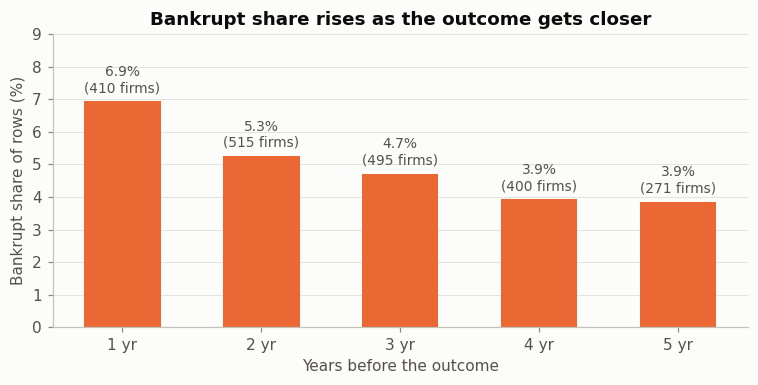

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.6))
x = balance.index
bars = ax.bar(x, balance["bankrupt_%"], color=eda.BANKRUPT, width=0.55)
for bar, pct, n in zip(bars, balance["bankrupt_%"], balance["bankrupt"]):
    ax.annotate(f"{pct:.1f}%\n({n} firms)", (bar.get_x() + bar.get_width() / 2, pct),
                xytext=(0, 4), textcoords="offset points", ha="center", va="bottom",
                fontsize=9, color="#52514e")
ax.set_xticks(x, [f"{h} yr" for h in x])
ax.set_xlabel("Years before the outcome")
ax.set_ylabel("Bankrupt share of rows (%)")
ax.set_ylim(0, 9)
ax.set_title("Bankrupt share rises as the outcome gets closer")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_class_balance.png", bbox_inches="tight")
plt.show()

**Reading it.** Between 3.9% and 6.9% of rows are bankruptcies: a strongly imbalanced problem. This is why accuracy is useless here: a model that predicts "healthy" for everyone scores 93–96% accuracy and finds no bankruptcies. We will use PR-AUC, ROC-AUC, recall at a fixed false-positive rate and the Brier score instead.

The bankrupt share is highest 1 year before the outcome. That is consistent with the corrected horizon direction (and is a useful sanity check on it).

## 3. Data quality

### 3a. Duplicate rows

In [6]:
dup_mask = df.duplicated(subset=FEATURE_COLUMNS, keep=False)
n_extra = df.duplicated(subset=FEATURE_COLUMNS).sum()
conflicts = (df[dup_mask].groupby(FEATURE_COLUMNS, dropna=False)["class"].nunique() > 1).sum()
cross_file = df.duplicated(subset=FEATURE_COLUMNS).sum() - df.duplicated(subset=FEATURE_COLUMNS + ["file_year"]).sum()

print(f"Rows that are an exact copy of an earlier row: {n_extra}")
print(f"Copies with conflicting labels: {conflicts}")
print(f"Copies that span two different files: {cross_file}")
print("\nRows involved in duplication, by class:")
print(df.loc[dup_mask, "class"].map(eda.CLASS_LABELS).value_counts().to_string())

Rows that are an exact copy of an earlier row: 401
Copies with conflicting labels: 0
Copies that span two different files: 0

Rows involved in duplication, by class:
class
Healthy     786
Bankrupt     16


**Reading it.** 401 rows are exact copies of another row in the *same* file, with identical labels, and almost all are healthy firms. They are probably data-entry duplicates, though they could in principle be different firms with identical ratios (unlikely across 64 continuous values).

**Why it matters:** with a random train/test split, one copy can land in training and the other in test. The model is then tested on a row it has already seen, which inflates scores. **Decision:** drop exact duplicates within each file before splitting.

### 3b. The dataset was pre-filtered

Every ARFF header contains `SubsetByExpression -E "not ismissing(ATT20)"`. The authors removed all rows where `Attr20` (inventory days) was missing *before* publishing. We cannot know how many rows were removed or whether they were disproportionately bankrupt. **This is a selection effect to report as a limitation**: the published sample is not a random sample of Polish companies.

In [7]:
print(f"Missing values in Attr20 after the authors' filter: {df['Attr20'].isna().sum()}")

Missing values in Attr20 after the authors' filter: 127


### 3c. Redundant columns

Some attributes are mathematically the same quantity. These were found from the definitions and verified on the data:

In [8]:
def share_equal(a: pd.Series, b: pd.Series) -> float:
    both = a.notna() & b.notna() & np.isfinite(b)
    return np.isclose(a[both], b[both], rtol=1e-3, atol=1e-3).mean()

checks = {
    "Attr14 = Attr7":          share_equal(df["Attr14"], df["Attr7"]),
    "Attr18 = Attr7":          share_equal(df["Attr18"], df["Attr7"]),
    "Attr17 = 1 / Attr2":      share_equal(df["Attr17"], 1 / df["Attr2"].replace(0, np.nan)),
    "Attr16 = 365 / Attr15":   share_equal(df["Attr16"], 365 / df["Attr15"].replace(0, np.nan)),
    "Attr43 = Attr44 + Attr20": share_equal(df["Attr43"], df["Attr44"] + df["Attr20"]),
    "Attr36 = Attr9 (same definition!)": share_equal(df["Attr36"], df["Attr9"]),
}
pd.Series(checks, name="share of rows equal").map("{:.1%}".format).to_frame()

,share of rows equal
Attr14 = Attr7,100.0%
Attr18 = Attr7,100.0%
Attr17 = 1 / Attr2,100.0%
Attr16 = 365 / Attr15,100.0%
Attr43 = Attr44 + Attr20,100.0%
Attr36 = Attr9 (same definition!),62.1%


**Reading it.**
- `Attr7` ("EBIT / total assets"), `Attr14` ("(gross profit + interest) / total assets") and `Attr18` ("gross profit / total assets") are **the same column** despite different definitions. The definitions are probably translation artefacts (Polish *zysk brutto* = profit before tax). Effective feature count: at most 62.
- `Attr17`, `Attr16` and `Attr43` are exact transformations of other columns. Tree models don't care, but in logistic regression these create perfect multicollinearity on a transformed scale.
- `Attr9` and `Attr36` have the *same documented definition* but differ in 38% of rows. "Total sales" probably includes other operating revenue. Keep both, but don't trust the documentation blindly.

**Decision:** drop `Attr14` and `Attr18` (exact copies). The transformed duplicates are handled in the feature-selection step for linear models.

## 4. Missing values

In [9]:
miss = eda.missingness_table(df)
rows_with_missing = df[FEATURE_COLUMNS].isna().any(axis=1).mean()
print(f"Rows with at least one missing value: {rows_with_missing:.1%}")
print(f"Attributes with any missing value: {(miss['missing_%'] > 0).sum()} of 64")
miss.head(12)[["missing_%", "missing_%_healthy", "missing_%_bankrupt", "ratio", "definition"]]

Rows with at least one missing value: 54.0%
Attributes with any missing value: 64 of 64


,missing_%,missing_%_healthy,missing_%_bankrupt,ratio,definition
Attr37,43.737,43.586,46.724,1.072,(current assets - inventories) / long-term liabilities
Attr21,13.487,12.681,29.412,2.319,sales (n) / sales (n-1)
Attr27,6.368,4.960,34.194,6.895,profit on operating activities / financial expenses
Attr60,4.958,4.783,8.417,1.760,sales / inventory
Attr45,4.946,4.771,8.417,1.764,net profit / inventory
Attr24,2.124,2.229,0.048,0.021,gross profit (in 3 years) / total assets
Attr28,1.871,1.772,3.826,2.159,working capital / fixed assets
Attr64,1.871,1.772,3.826,2.159,sales / fixed assets
Attr53,1.871,1.772,3.826,2.159,equity / fixed assets
Attr54,1.871,1.772,3.826,2.159,constant capital / fixed assets


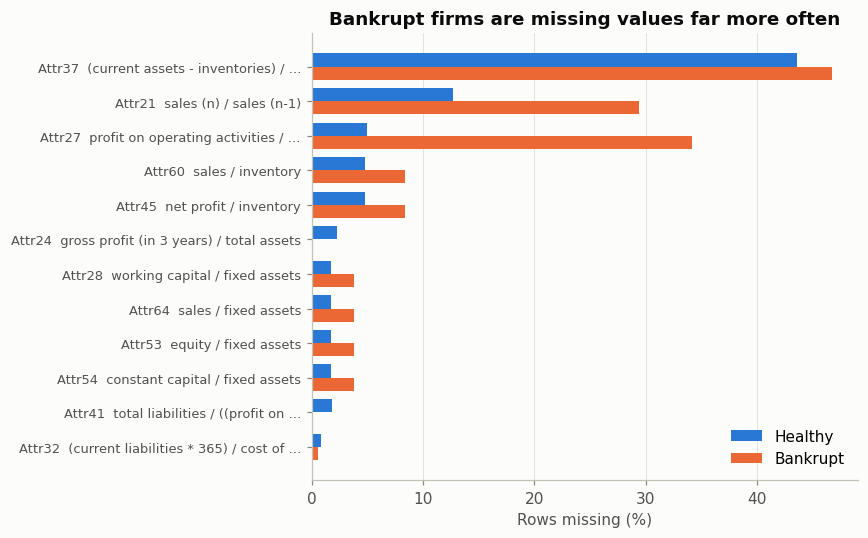

In [10]:
top = miss.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(top))
h = 0.38
ax.barh(y + h / 2, top["missing_%_healthy"], height=h, color=eda.HEALTHY, label="Healthy")
ax.barh(y - h / 2, top["missing_%_bankrupt"], height=h, color=eda.BANKRUPT, label="Bankrupt")
ax.set_yticks(y, [f"{a}  {eda.short(attrs.loc[a, 'definition'], 40)}" for a in top.index], fontsize=8.5)
ax.set_xlabel("Rows missing (%)")
ax.set_title("Bankrupt firms are missing values far more often")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_missingness_by_class.png", bbox_inches="tight")
plt.show()

**Reading it.** Missingness is **not random**; it carries information about the label:
- `Attr27` (interest coverage) is missing for 34% of bankrupt firms but 5% of healthy firms, about 7x more often.
- `Attr21` (sales growth needs last year's sales) is missing 2.3x more often for bankrupt firms.
- `Attr24` and `Attr41` go the other way: missing almost only for *healthy* firms. That looks like an artefact of how the data was collected rather than a property of the firms. A model that learns "missing Attr24 means safe" would not transfer to new data, so this is worth watching in the SHAP analysis later.

Why might `Attr37` be missing in 44% of rows? Its denominator is long-term liabilities. Firms with **no long-term debt** have an undefined ratio:

In [11]:
no_lt_debt = df["Attr59"] == 0  # Attr59 = long-term liabilities / equity
print(f"Attr37 missing:                          {df['Attr37'].isna().sum():,}")
print(f"... of which the firm has no long-term debt: {(df['Attr37'].isna() & no_lt_debt).sum():,}")

Attr37 missing:                          18,984
... of which the firm has no long-term debt: 18,978


So `Attr37` missing almost always means "no long-term debt", which is a real economic fact, not lost data. Imputing it with the median would invent a value that has no meaning.

Missingness at row level tells the same story:

In [12]:
n_missing = df[FEATURE_COLUMNS].isna().sum(axis=1)
by_count = df.groupby(n_missing.clip(upper=5))["class"].agg(rows="size", bankrupt_rate="mean")
by_count.index = [str(i) if i < 5 else "5+" for i in by_count.index]
by_count.index.name = "missing values in row"
by_count["bankrupt_rate"] = (100 * by_count["bankrupt_rate"]).map("{:.1f}%".format)
by_count

,rows,bankrupt_rate
missing values in row,,
0,19967,2.2%
1,16060,5.7%
2,4134,11.6%
3,1431,7.5%
4,588,9.7%
5+,1225,7.9%


**Decision for modelling:**
- **Gradient boosting** (LightGBM) handles NaN natively: it learns which branch missing values should go to, so it can exploit informative missingness directly.
- **Logistic regression** needs imputation. We impute with the training-fold median (inside the `Pipeline`) **and** add binary "was missing" indicator columns for the attributes where missingness is informative. Without the indicators, the signal shown above is thrown away.

## 5. Distributions and outliers

In [13]:
pct = eda.percentile_summary(df)
pct.sort_values("tail_ratio", ascending=False).head(10)

,min,p1,p25,median,p75,p99,max,tail_ratio,category
Attr56,"-1,108,300.000",-0.663,0.009,0.053,0.129,0.987,293.150,"1,123,221.207",profitability
Attr58,-198.690,0.048,0.875,0.951,0.993,1.658,"1,108,300.000","668,294.742",profitability
Attr44,"-115,870.000",2.958,34.878,54.767,80.522,441.419,"22,584,000.000","51,162.263",activity
Attr43,"-115,870.000",9.691,66.608,99.401,140.697,659.646,"30,393,000.000","46,074.706",activity
Attr41,"-1,234.400",-2.202,0.027,0.086,0.206,7.492,"288,770.000","38,545.838",leverage
Attr30,"-6,351.700",-0.627,0.083,0.217,0.409,4.202,"152,860.000","36,378.218",leverage
Attr20,-29.340,0.000,15.413,35.150,63.723,274.385,"7,809,200.000","28,460.719",activity
Attr62,"-2,336,500.000",4.934,42.144,71.326,117.220,915.716,"25,016,000.000","27,318.529",activity
Attr52,-25.467,0.014,0.127,0.214,0.350,3.242,"88,433.000","27,281.186",activity
Attr13,"-1,460.600",-0.575,0.024,0.068,0.135,0.768,"13,315.000","17,332.866",profitability


**Reading it.** The tails are extreme. Take `Attr56` (gross margin): the middle 98% of firms lie between −0.66 and about 1, yet the minimum is −1,108,300. A margin of −110 million percent is not economics: it comes from **dividing by a near-zero denominator** (a firm with almost no sales). Many ratios here have the same problem.

**Consequences:**
- **Mean and standard deviation are meaningless** for these columns; medians and percentiles are the right summaries.
- **Logistic regression** is badly hurt by such values (one point can dominate the fit). We will **winsorise** (clip each feature at percentiles learned on the training fold, e.g. 1st/99th), then optionally apply a signed log transform.
- **Tree models** split on ranks, so they are largely immune.

Below: the distribution of a few key ratios for each class, with the axis cut at the 1st–95th percentile *for display only* (otherwise the long right tails squash everything into one bar).

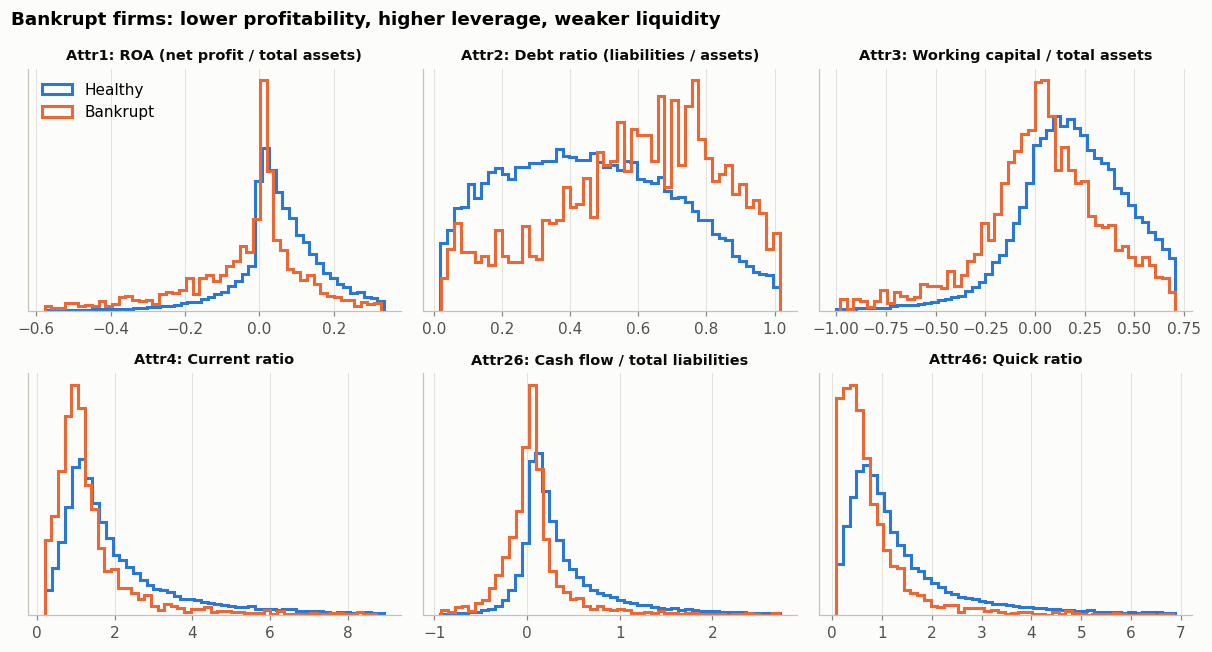

In [14]:
key = {
    "Attr1": "ROA (net profit / total assets)",
    "Attr2": "Debt ratio (liabilities / assets)",
    "Attr3": "Working capital / total assets",
    "Attr4": "Current ratio",
    "Attr26": "Cash flow / total liabilities",
    "Attr46": "Quick ratio",
}
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, (col, name) in zip(axes.flat, key.items()):
    lo, hi = df[col].quantile([0.01, 0.95])
    for cls in (0, 1):
        vals = df.loc[df["class"] == cls, col].dropna()
        vals = vals[(vals >= lo) & (vals <= hi)]
        ax.hist(vals, bins=50, density=True, histtype="step", linewidth=2,
                color=eda.CLASS_COLORS[cls], label=eda.CLASS_LABELS[cls])
    ax.set_title(f"{col}: {name}", fontsize=9.5)
    ax.set_yticks([])
axes.flat[0].legend(loc="upper left")
fig.suptitle("Bankrupt firms: lower profitability, higher leverage, weaker liquidity",
             fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_key_distributions.png", bbox_inches="tight")
plt.show()

**Reading it.** The orange curves (bankrupt) sit to the left on profitability (`Attr1` ROA), coverage (`Attr26`) and liquidity (`Attr3`, `Attr4`, `Attr46`) and to the right on leverage (`Attr2` debt ratio). That is exactly what credit theory predicts, which is reassuring. But the curves **overlap heavily**: no single ratio separates the classes, which is why a multivariate model is needed.

## 6. Which ratios separate bankrupt from healthy firms?

For each attribute alone we compute the **univariate ROC-AUC**: how well does ranking firms by that one ratio separate the classes?
- AUC = 0.5: no signal; AUC < 0.5: *lower* values are riskier (e.g. profitability).
- `strength` = |AUC − 0.5| × 2, from 0 (none) to 1 (perfect).

AUC uses only the ranking of values, so it is unaffected by the outliers in section 5.

In [15]:
sep = eda.separation_table(df)
sep.head(15)[["auc", "strength", "direction", "category", "definition"]]

,auc,strength,direction,category,definition
Attr26,0.277,0.446,lower = riskier,leverage,(net profit + depreciation) / total liabilities
Attr16,0.279,0.442,lower = riskier,leverage,(gross profit + depreciation) / total liabilities
Attr13,0.286,0.428,lower = riskier,profitability,(gross profit + depreciation) / sales
Attr46,0.298,0.404,lower = riskier,liquidity,(current assets - inventory) / short-term liabilities
Attr12,0.301,0.399,lower = riskier,leverage,gross profit / short-term liabilities
Attr24,0.301,0.398,lower = riskier,profitability,gross profit (in 3 years) / total assets
Attr23,0.306,0.388,lower = riskier,profitability,net profit / sales
Attr19,0.307,0.385,lower = riskier,profitability,gross profit / sales
Attr31,0.312,0.375,lower = riskier,profitability,(gross profit + interest) / sales
Attr45,0.312,0.375,lower = riskier,profitability,net profit / inventory


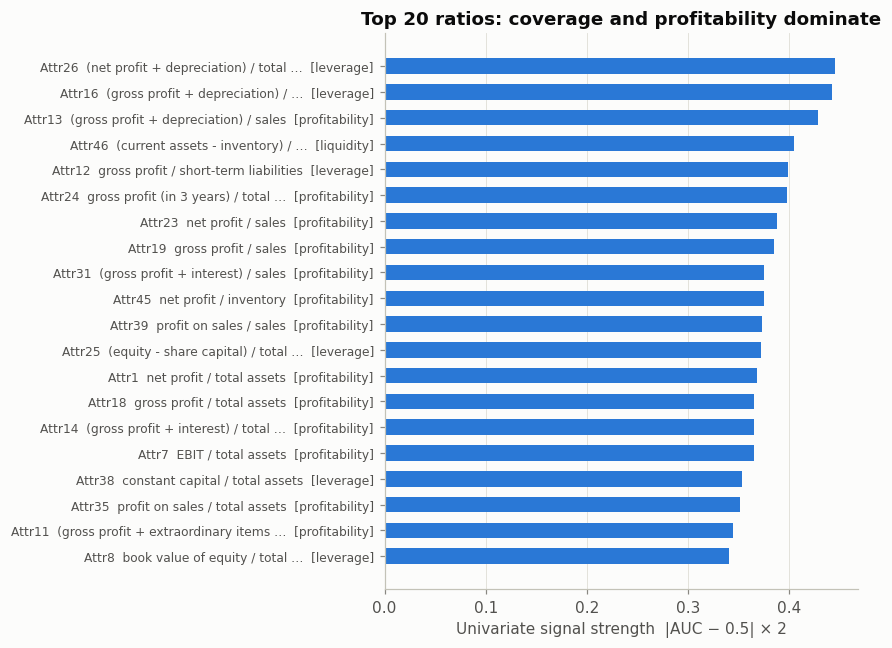

In [16]:
top = sep.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(np.arange(len(top)), top["strength"], color=eda.HEALTHY, height=0.6)
ax.set_yticks(np.arange(len(top)),
              [f"{a}  {eda.short(attrs.loc[a, 'definition'], 38)}  [{attrs.loc[a, 'category']}]" for a in top.index],
              fontsize=8)
ax.set_xlabel("Univariate signal strength  |AUC − 0.5| × 2")
ax.set_title("Top 20 ratios: coverage and profitability dominate")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_univariate_signal.png", bbox_inches="tight")
plt.show()

In [17]:
sep.groupby("category")["strength"].agg(["mean", "max", "size"]).sort_values("mean", ascending=False)

,mean,max,size
category,,,
profitability,0.340,0.428,20
leverage,0.278,0.446,18
liquidity,0.267,0.404,11
size,0.129,0.129,1
activity,0.111,0.287,14


**Reading it.**
- The strongest single ratios are **cash flow to debt** (`Attr26`, `Attr16`), **margins** (`Attr13`, `Attr23`, `Attr19`) and the **quick ratio** (`Attr46`). This matches the credit-analysis intuition: firms fail when they can't generate enough cash to service their debt.
- **Activity/efficiency** ratios carry little signal on their own.
- Even the best single ratio reaches a strength of only ~0.45 (AUC ≈ 0.72 in the "lower = riskier" direction). There is real signal, but no single ratio is enough.

### Does the signal weaken further from the outcome?

In [18]:
top5 = sep.index[:5]
by_h = pd.DataFrame({
    h: {f: abs(eda.univariate_auc(g, f) - 0.5) * 2 for f in top5}
    for h, g in df.groupby("years_before_outcome")
})
by_h.columns.name = "years before outcome"
by_h

years before outcome,1,2,3,4,5
Attr26,0.592,0.444,0.439,0.324,0.418
Attr16,0.589,0.442,0.432,0.323,0.410
Attr13,0.569,0.431,0.423,0.285,0.426
Attr46,0.505,0.423,0.375,0.346,0.381
Attr12,0.558,0.403,0.376,0.268,0.385


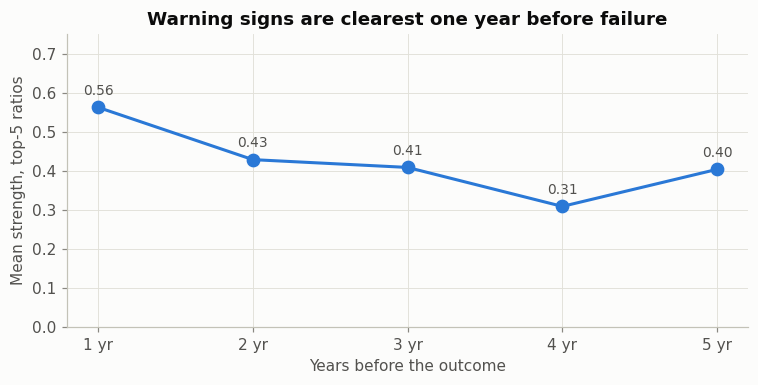

In [19]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(by_h.columns, by_h.mean(), marker="o", markersize=8, linewidth=2, color=eda.HEALTHY)
for h, v in by_h.mean().items():
    ax.annotate(f"{v:.2f}", (h, v), xytext=(0, 8), textcoords="offset points",
                ha="center", fontsize=9, color="#52514e")
ax.set_xticks(by_h.columns, [f"{h} yr" for h in by_h.columns])
ax.set_xlabel("Years before the outcome")
ax.set_ylabel("Mean strength, top-5 ratios")
ax.set_ylim(0, 0.75)
ax.set_title("Warning signs are clearest one year before failure")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_signal_by_horizon.png", bbox_inches="tight")
plt.show()

**Reading it.** The signal is clearly strongest **1 year before** the outcome (0.56). Beyond that it drops to roughly 0.3–0.4 and is **not monotonic**: the 5-year horizon (0.40) scores higher than the 4-year one (0.31). Possible reasons, which we cannot separate with this data: the 5-year file has the fewest bankruptcies (271), so its estimate is the noisiest; and each file is a different sample of firms, so horizons are not a clean "same firms, earlier in time" comparison. The honest summary is: *one year out is much easier; beyond that, the signal is weaker and of roughly similar size.*

This is the central trade-off in choosing a horizon:
- **1 year before:** easiest to predict, but by then it is often too late for a lender to act.
- **Longer horizons:** more useful early warning, but weaker signal and fewer positives.

## 7. Correlation and redundancy

We use **Spearman** (rank) correlation, because Pearson correlation would be dominated by the outliers in section 5. Attributes are ordered by category so that blocks of related ratios are visible.

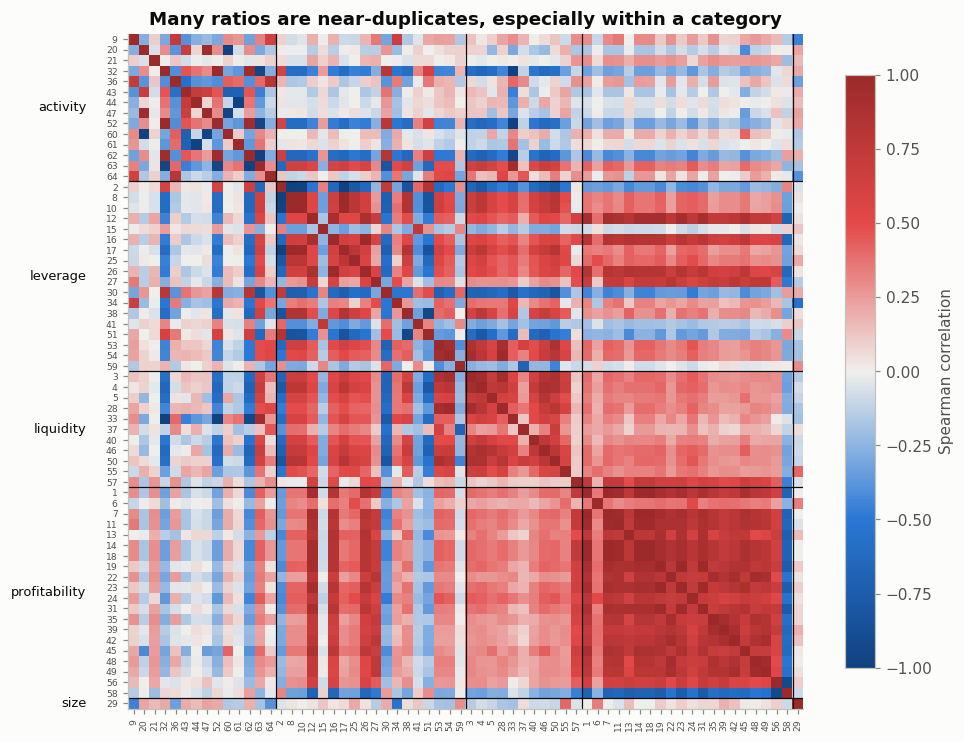

In [20]:
order = attrs.sort_values(["category", "number"]).index
corr = df[order].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap=eda.DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(order)), [a.replace("Attr", "") for a in order], fontsize=6, rotation=90)
ax.set_yticks(range(len(order)), [a.replace("Attr", "") for a in order], fontsize=6)
ax.grid(False)
# Mark category boundaries.
cats = attrs.loc[order, "category"].to_numpy()
bounds = [i for i in range(1, len(cats)) if cats[i] != cats[i - 1]]
for b in bounds:
    ax.axhline(b - 0.5, color="#0b0b0b", linewidth=0.8)
    ax.axvline(b - 0.5, color="#0b0b0b", linewidth=0.8)
starts = [0] + bounds
ends = bounds + [len(cats)]
for s, e in zip(starts, ends):
    ax.text(-4.5, (s + e - 1) / 2, cats[s], ha="right", va="center", fontsize=8.5,
            color="#0b0b0b", clip_on=False)
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman correlation")
ax.set_title("Many ratios are near-duplicates, especially within a category")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_correlation_heatmap.png", bbox_inches="tight")
plt.show()

In [21]:
pairs = eda.high_correlation_pairs(corr, threshold=0.95)
print(f"Pairs with |Spearman rho| >= 0.95: {len(pairs)}")
pairs.assign(
    def_a=pairs["attr_a"].map(attrs["definition"]).str[:35],
    def_b=pairs["attr_b"].map(attrs["definition"]).str[:35],
).head(15)

Pairs with |Spearman rho| >= 0.95: 35


,attr_a,attr_b,rho,def_a,def_b
1896,Attr14,Attr18,1.000,(gross profit + interest) / total a,gross profit / total assets
1847,Attr7,Attr14,1.000,EBIT / total assets,(gross profit + interest) / total a
70,Attr20,Attr60,-1.000,(inventory * 365) / sales,sales / inventory
1848,Attr7,Attr18,1.000,EBIT / total assets,gross profit / total assets
796,Attr2,Attr17,-1.000,total liabilities / total assets,total assets / total liabilities
638,Attr62,Attr63,-0.999,(short-term liabilities *365) / sal,sales / short-term liabilities
366,Attr44,Attr61,-0.999,(receivables * 365) / sales,sales / receivables
190,Attr32,Attr52,0.998,(current liabilities * 365) / cost,(short-term liabilities * 365) / co
503,Attr52,Attr33,-0.998,(short-term liabilities * 365) / co,operating expenses / short-term lia
218,Attr32,Attr33,-0.997,(current liabilities * 365) / cost,operating expenses / short-term lia


**Reading it.** 35 pairs have |ρ| ≥ 0.95. Beyond the exact duplicates in section 3c, these include:
- inverse pairs (`Attr20` inventory days vs `Attr60` inventory turnover, ρ = −1.00; `Attr44` vs `Attr61`; `Attr62` vs `Attr63`);
- the same numerator over similar denominators (`Attr1` ROA vs `Attr7` EBIT/TA, ρ = 0.99);
- the leverage block (`Attr2`, `Attr8`, `Attr10`, `Attr17`), which are all versions of "how much of the balance sheet is debt".

**Consequences:**
- For **logistic regression**, near-collinear features make coefficients unstable and uninterpretable. Use regularisation (L2/L1) and/or keep one representative per correlated group.
- For **SHAP** explanations, credit gets split arbitrarily between correlated features. When explaining a prediction we should report importance at the **category level** as well (e.g. "leverage") and not over-interpret one ratio versus its twin.

### Altman Z' inputs

All five inputs of Altman's Z' model (the 1983 private-firm version, which uses *book* equity) exist in the data as-is, so the baseline needs no approximation:

In [22]:
pd.DataFrame({
    "coefficient": ALTMAN_Z_PRIME,
    "definition": attrs.loc[list(ALTMAN_Z_PRIME), "definition"],
    "missing_%": miss.loc[list(ALTMAN_Z_PRIME), "missing_%"],
    "univariate_strength": sep.loc[list(ALTMAN_Z_PRIME), "strength"],
})

,coefficient,definition,missing_%,univariate_strength
Attr3,0.717,working capital / total assets,0.018,0.305
Attr6,0.847,retained earnings / total assets,0.018,0.279
Attr7,3.107,EBIT / total assets,0.018,0.365
Attr8,0.420,book value of equity / total liabilities,0.217,0.341
Attr9,0.998,sales / total assets,0.021,0.069


## 8. Summary of findings and decisions

| # | Finding | Decision / consequence |
|---|---|---|
| 1 | `Nyear.arff` is **6 − N** years before the outcome, not N. | Use `years_before_outcome` everywhere; CLAUDE.md corrected. |
| 2 | Imbalance: 3.9–6.9% bankrupt depending on horizon. | No accuracy. PR-AUC, ROC-AUC, recall at fixed FPR, Brier. Class weights / threshold tuning. |
| 3 | 401 exact duplicate rows (within files, mostly healthy). | Drop before splitting, so copies can't straddle train and test. |
| 4 | The authors pre-filtered rows with missing `Attr20`. | Report as a sample-selection limitation. |
| 5 | `Attr7 = Attr14 = Attr18`; `Attr17`, `Attr16`, `Attr43` are exact transforms. 35 pairs with \|ρ\| ≥ 0.95. | Drop `Attr14`, `Attr18`. Regularise LR; read SHAP at category level too. |
| 6 | 54% of rows have a missing value; **missingness predicts bankruptcy** (`Attr27` missing 7x more for bankrupt firms). | LightGBM: native NaN. LR: training-fold median imputation + missing-indicator columns. |
| 7 | `Attr37` missing ⇔ no long-term debt. | Missingness is an economic fact; the indicator captures it. |
| 8 | `Attr24`, `Attr41` missing almost only for healthy firms. | Likely a collection artefact. Check that models don't lean on it (SHAP). |
| 9 | Extreme tails from near-zero denominators (e.g. a margin of −1.1M). | Medians not means. Winsorise for LR (fit on training folds). Trees are robust. |
| 10 | Strongest signal: cash flow to debt, margins, quick ratio; activity ratios weak. | Consistent with credit theory; a good story for the SHAP section. |
| 11 | Signal is strongest 1 year before the outcome (0.56); at 2–5 years it is weaker (0.31–0.43) and not monotonic. | Horizon choice is a trade-off; decided in the next step. |

**Open questions for the next step (prediction target, horizon and validation):**
- Model the 1-year horizon only, each horizon separately, or pool them with `years_before_outcome` as a feature?
- There are no dates and no company IDs, so the split has to be random (stratified). That is a limitation to state clearly, and it means we cannot rule out the same firm appearing in train and test across different horizons.